Workflow:
- Scaricare il dataset
- Modellare il dataset: rimuovere colonne, valori mancanti
- Selezione delle feature: quelle che non sono molto correlate tra loro

- Split dei dati: 80/20
- Primo modello di Decision Tree -> dummy
- Tuning degli iperparametri: prima Random Search poi Grid Search
- Pruning dell'albero trovato
- Secondo modello di Decision Tree -> migliore

- Provare a dare un peso per le varie istanze !

- Bagging e Boosting classici sui modelli ottimizzati
- Random Forest -> dummy
- Tuning dei parametri della Random Forest
- Con Random Forest: trova le migliori feature, Outliers e missing value imputation 

- Creazione di nuove feature? Magari combinare alcune che erano molto correlate in una sola ???

In [236]:
import numpy as np
import pandas as pd


# Scarichiamo e leggiamo i dati del train.csv file
df = pd.read_csv("dati/train.csv")
df.head()

,id,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,...,PCIAT-PCIAT_18,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii
0,00008ff9,Fall,5,0,Winter,51,Fall,16.87731569,46.0,50.8,...,4,2,4,55,,,,Fall,3,2
1,000fd460,Summer,9,0,,,Fall,14.03559028,48.0,46.0,...,0,0,0,0,Fall,46,64,Summer,0,0
2,00105258,Summer,10,1,Fall,71,Fall,16.64869606,56.5,75.6,...,2,1,1,28,Fall,38,54,Summer,2,0
3,00115b9f,Winter,9,0,Fall,71,Summer,18.29234694,56.0,81.6,...,3,4,1,44,Summer,31,45,Winter,0,1
4,0016bb22,Spring,18,1,Summer,,,,,,...,,,,,,,,,,


In [237]:
print("Valori da predire:", df['sii'].unique())
print("Valori nulli nella colonna target:", df['sii'].isna().sum())
print("Tipo della classe target:", df['sii'].dtype)

Valori da predire: ['  2' '  0' '  1' '   ' '  3']
Valori nulli nella colonna target: 0
Tipo della classe target: object


In [238]:
# I dati mancanti non sono NaN, ma sono spazi ("   ")
# Sostituiamo le stringhe vuote della colonna 'sii' ("   ") con NaN
df['sii'] = df['sii'].str.strip()
df['sii'] = df['sii'].replace("", np.nan)
print("Valori nulli nella colonna target prima del drop:", df['sii'].isna().sum())

# Eliminiamuo le righe con valori NaN nella colonna 'sii'
df = df.dropna(subset=['sii'])
print("Valori nulli nella colonna target dopo il drop:", df['sii'].isna().sum())

# Convertiamo la colonna 'sii' in numerica
df['sii'] = df['sii'].astype(float)
print("Tipo della classe target:", df['sii'].dtype)

Valori nulli nella colonna target prima del drop: 1224
Valori nulli nella colonna target dopo il drop: 0
Tipo della classe target: float64


In [239]:
# Sostituisco tutti i valori nulli nel dataset, che sono spazi "   ", con NaN
for col in df.select_dtypes(include=['object']).columns: 
    df[col] = df[col].str.strip()
    df[col] = df[col].replace(r'^\s*$', np.nan, regex=True)

In [240]:
# Traduciamo le varibili categoriali in numeriche
categorical_features = [col for col in df.columns if col.endswith("_Season ") or col.endswith("-Season ")]
season_mapping = {
    "Summer": 0,
    "Fall": 1,
    "Winter": 2,
    "Spring": 3,
}

for col in categorical_features:
    # df[col].fillna(df[col].mode()[0], inplace=True) # rimpiazziamo il valore nullo con la moda
    df[col] = df[col].map(season_mapping)

# Eliminiamo la colonna id -> non serve
# traduciamo l'intero dataset in float
# Eliminiamo le righe che hanno peso == 0 -> impossibile
# Sostiuiamo i valori nulli con la media della rispettiva colonna

df = df.drop(columns=['id       ', 'SDS-SDS_Total_Raw '])
df = df.astype(float)

print(df["Physical-Weight "].min())
print(df["Physical-Weight "].max())

zero_weight_rows = df[df['Physical-Weight '] == 0]
zero_weight_indices = zero_weight_rows.index 

df = df.drop(zero_weight_indices)
print(f"Numero di osservazioni dopo la rimozione: {df.shape[0]}")

0.0
315.0
Numero di osservazioni dopo la rimozione: 2684


In [241]:
# Elimino le colonne che hanno più del 40% di valori mancanti e che non sono molto correlate con la variabile target
missing_threshold = 0.4

missing_percentage = df.isnull().mean()

columns_to_drop = missing_percentage[missing_percentage > missing_threshold].index
# df = df.drop(columns=columns_to_drop)

print(f"Columns dropped: {list(columns_to_drop)}")

correlation_with_target = df[columns_to_drop].corrwith(df['sii']).abs().sort_values(ascending=False)

print("Correlation of high-missing features with target:")
print(correlation_with_target)

high_corr_features = correlation_with_target[correlation_with_target > 0.10].index  
columns_to_really_drop = set(columns_to_drop) - set(high_corr_features)

print(f"Columns actually dropped: {list(columns_to_really_drop)}")
print(f"Columns retained due to correlation: {list(high_corr_features)}")

df = df.drop(columns=columns_to_really_drop)

Columns dropped: ['Physical-Waist_Circumference ', 'Fitness_Endurance-Season ', 'Fitness_Endurance-Max_Stage ', 'Fitness_Endurance-Time_Mins ', 'Fitness_Endurance-Time_Sec ', 'FGC-FGC_GSND ', 'FGC-FGC_GSND_Zone ', 'FGC-FGC_GSD ', 'FGC-FGC_GSD_Zone ', 'PAQ_A-Season ', 'PAQ_A-PAQ_A_Total ', 'PAQ_C-Season ', 'PAQ_C-PAQ_C_Total ']
Correlation of high-missing features with target:
Physical-Waist_Circumference     0.272885
FGC-FGC_GSD                      0.163448
FGC-FGC_GSND                     0.149495
Fitness_Endurance-Max_Stage      0.070589
Fitness_Endurance-Time_Mins      0.060628
PAQ_A-PAQ_A_Total                0.045968
PAQ_C-Season                     0.032939
PAQ_A-Season                     0.025298
FGC-FGC_GSD_Zone                 0.023696
Fitness_Endurance-Time_Sec       0.008701
PAQ_C-PAQ_C_Total                0.004365
Fitness_Endurance-Season         0.003978
FGC-FGC_GSND_Zone                0.001667
dtype: float64
Columns actually dropped: ['Fitness_Endurance-Max_Stage ', '

In [242]:

df['BMI_total'] = df[['BIA-BIA_BMI ', 'Physical-BMI ']].mean(axis=1)

df = df.drop(columns=['BIA-BIA_BMI ', 'Physical-BMI '])

for col in df.columns:
   df[col].fillna(round(df[col].mean()), inplace=True)

df = df.round(2)

C:\Users\Utente\AppData\Local\Temp\ipykernel_17132\3915287253.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(round(df[col].mean()), inplace=True)


In [243]:
# la colonna sii è derivata direttamente dalle colonne PCIAT-PCIAT_* -> non possiamo tenerle in considerazione
X = df.drop(columns=['sii'] + [col for col in df.columns if col.startswith('PCIAT-PCIAT') or col.startswith('PCIAT')])
y = df['sii']
X.shape, y.shape

((2684, 46), (2684,))

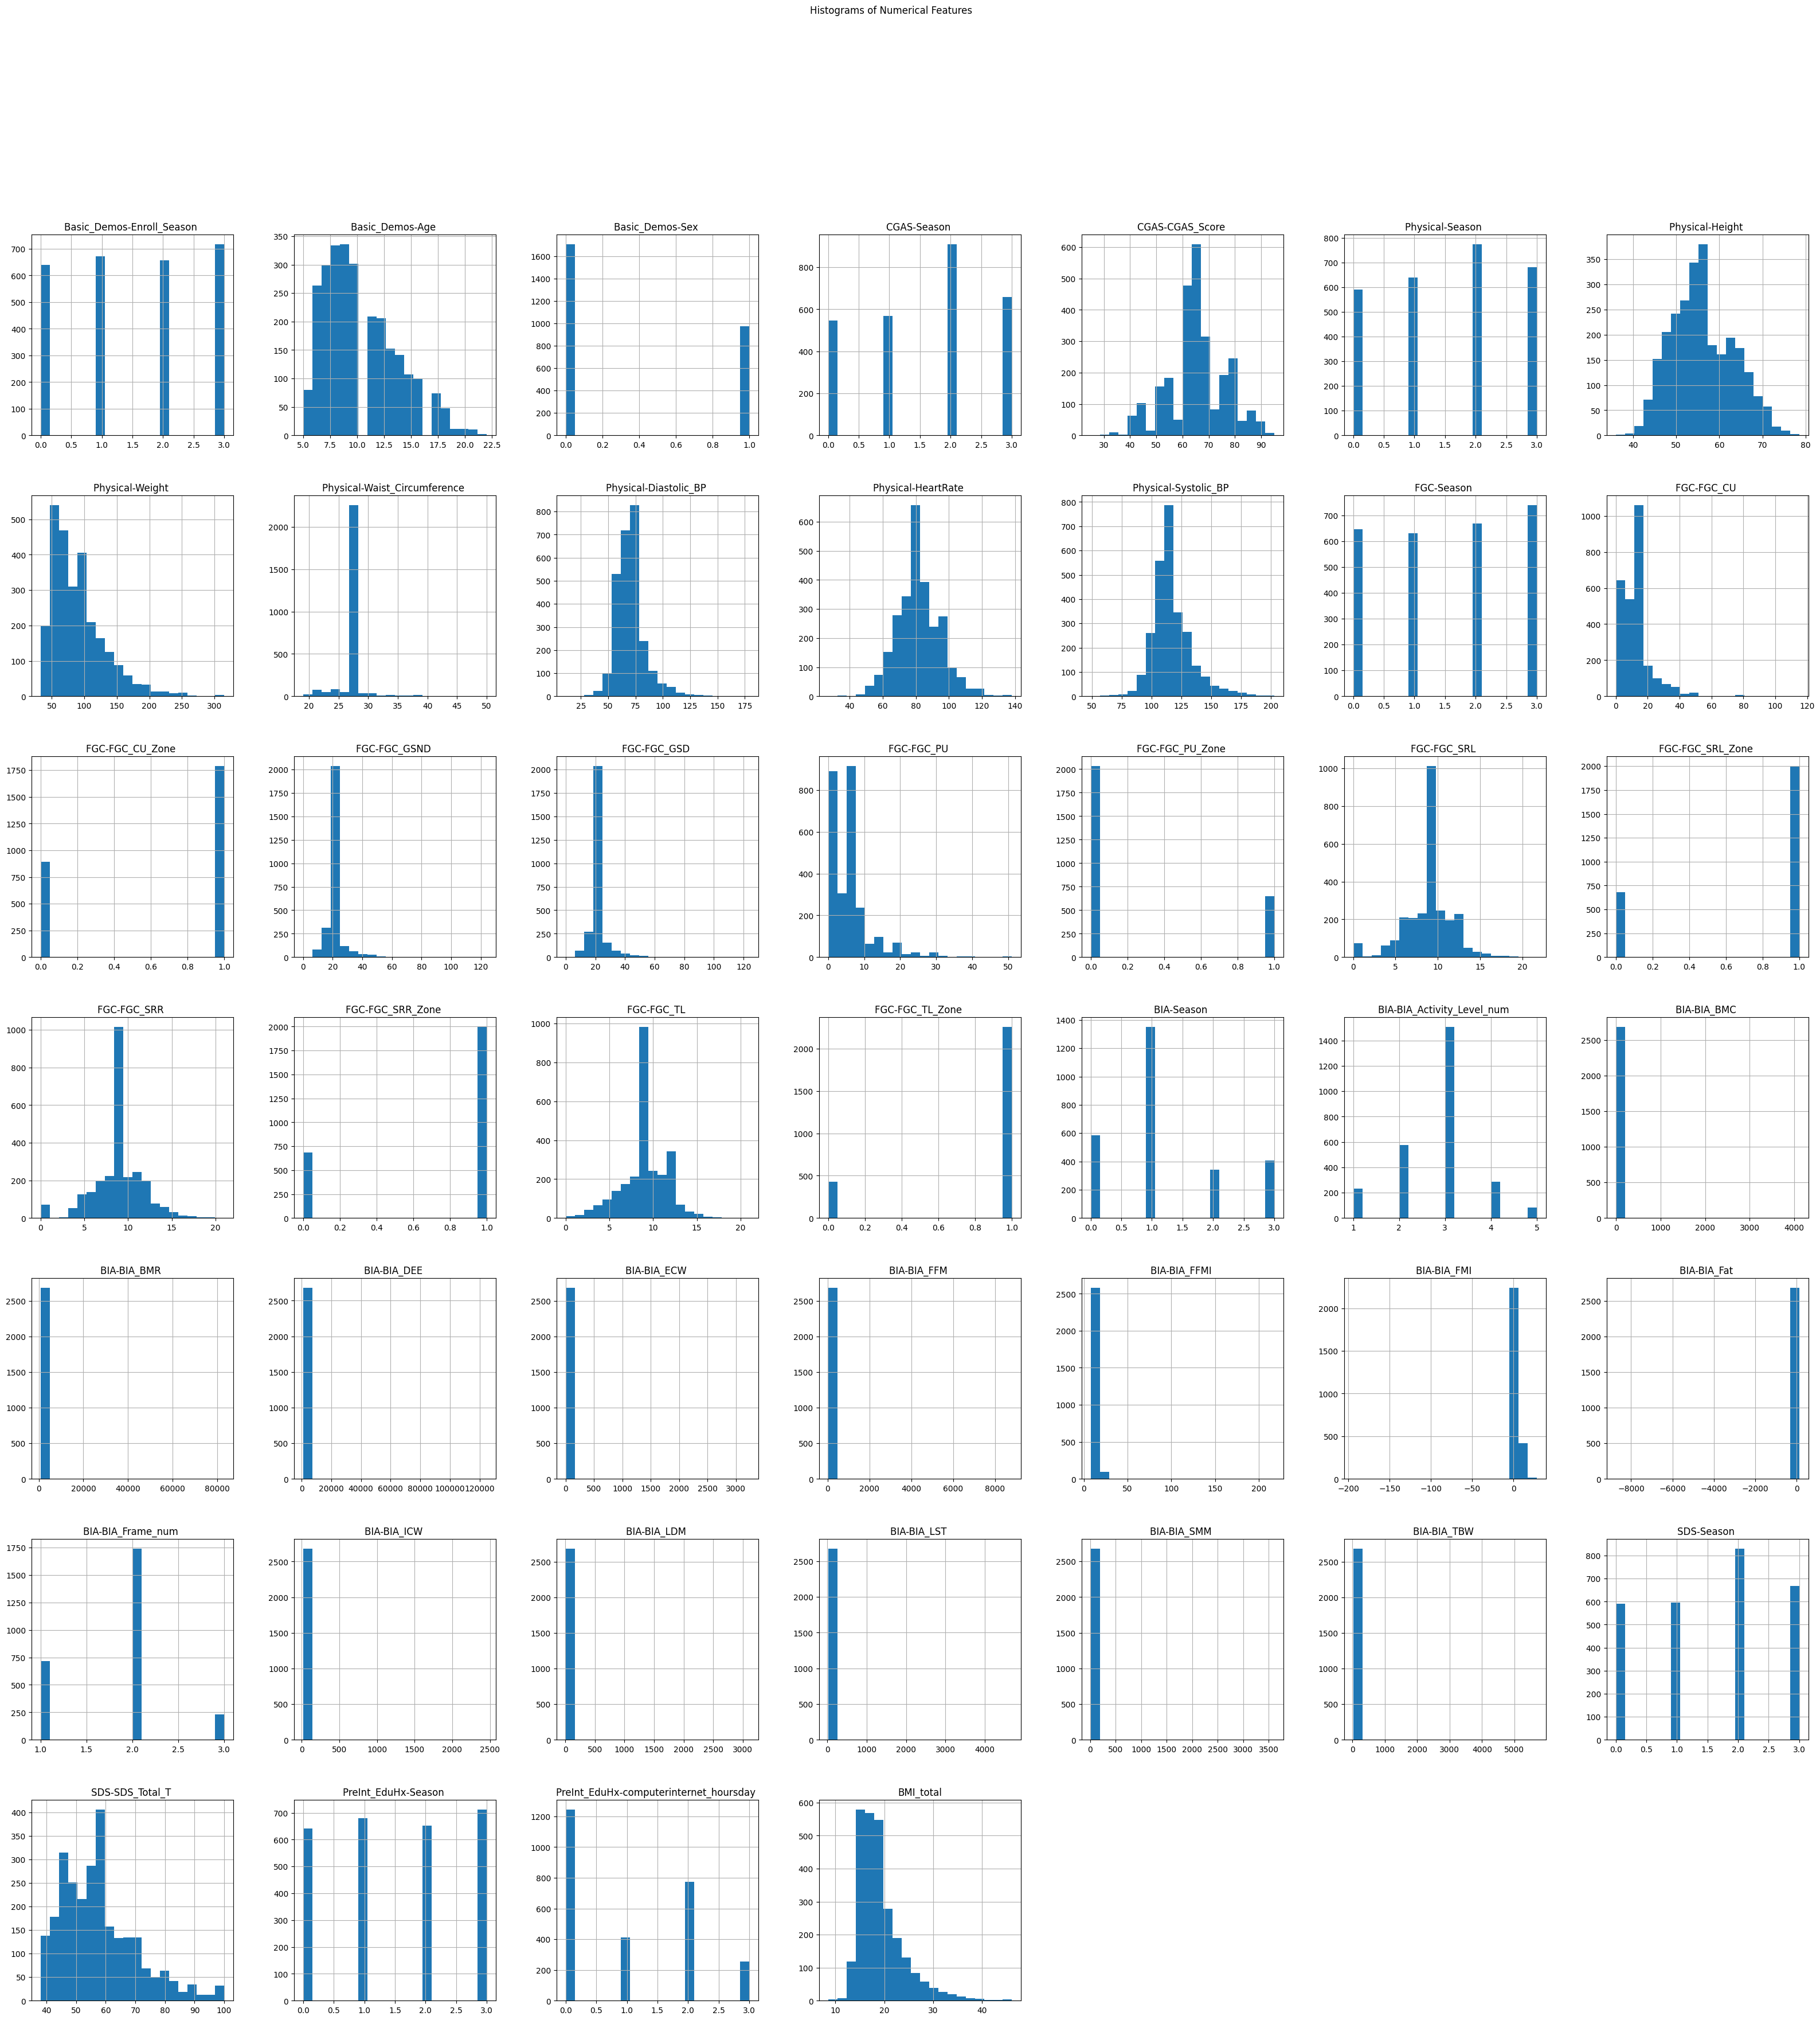

In [244]:
# Visualizzo le varibili usando gli istogrammi
import matplotlib.pyplot as plt

X.hist(bins=20, figsize=(40, 40))
plt.suptitle("Histograms of Numerical Features")
plt.show()


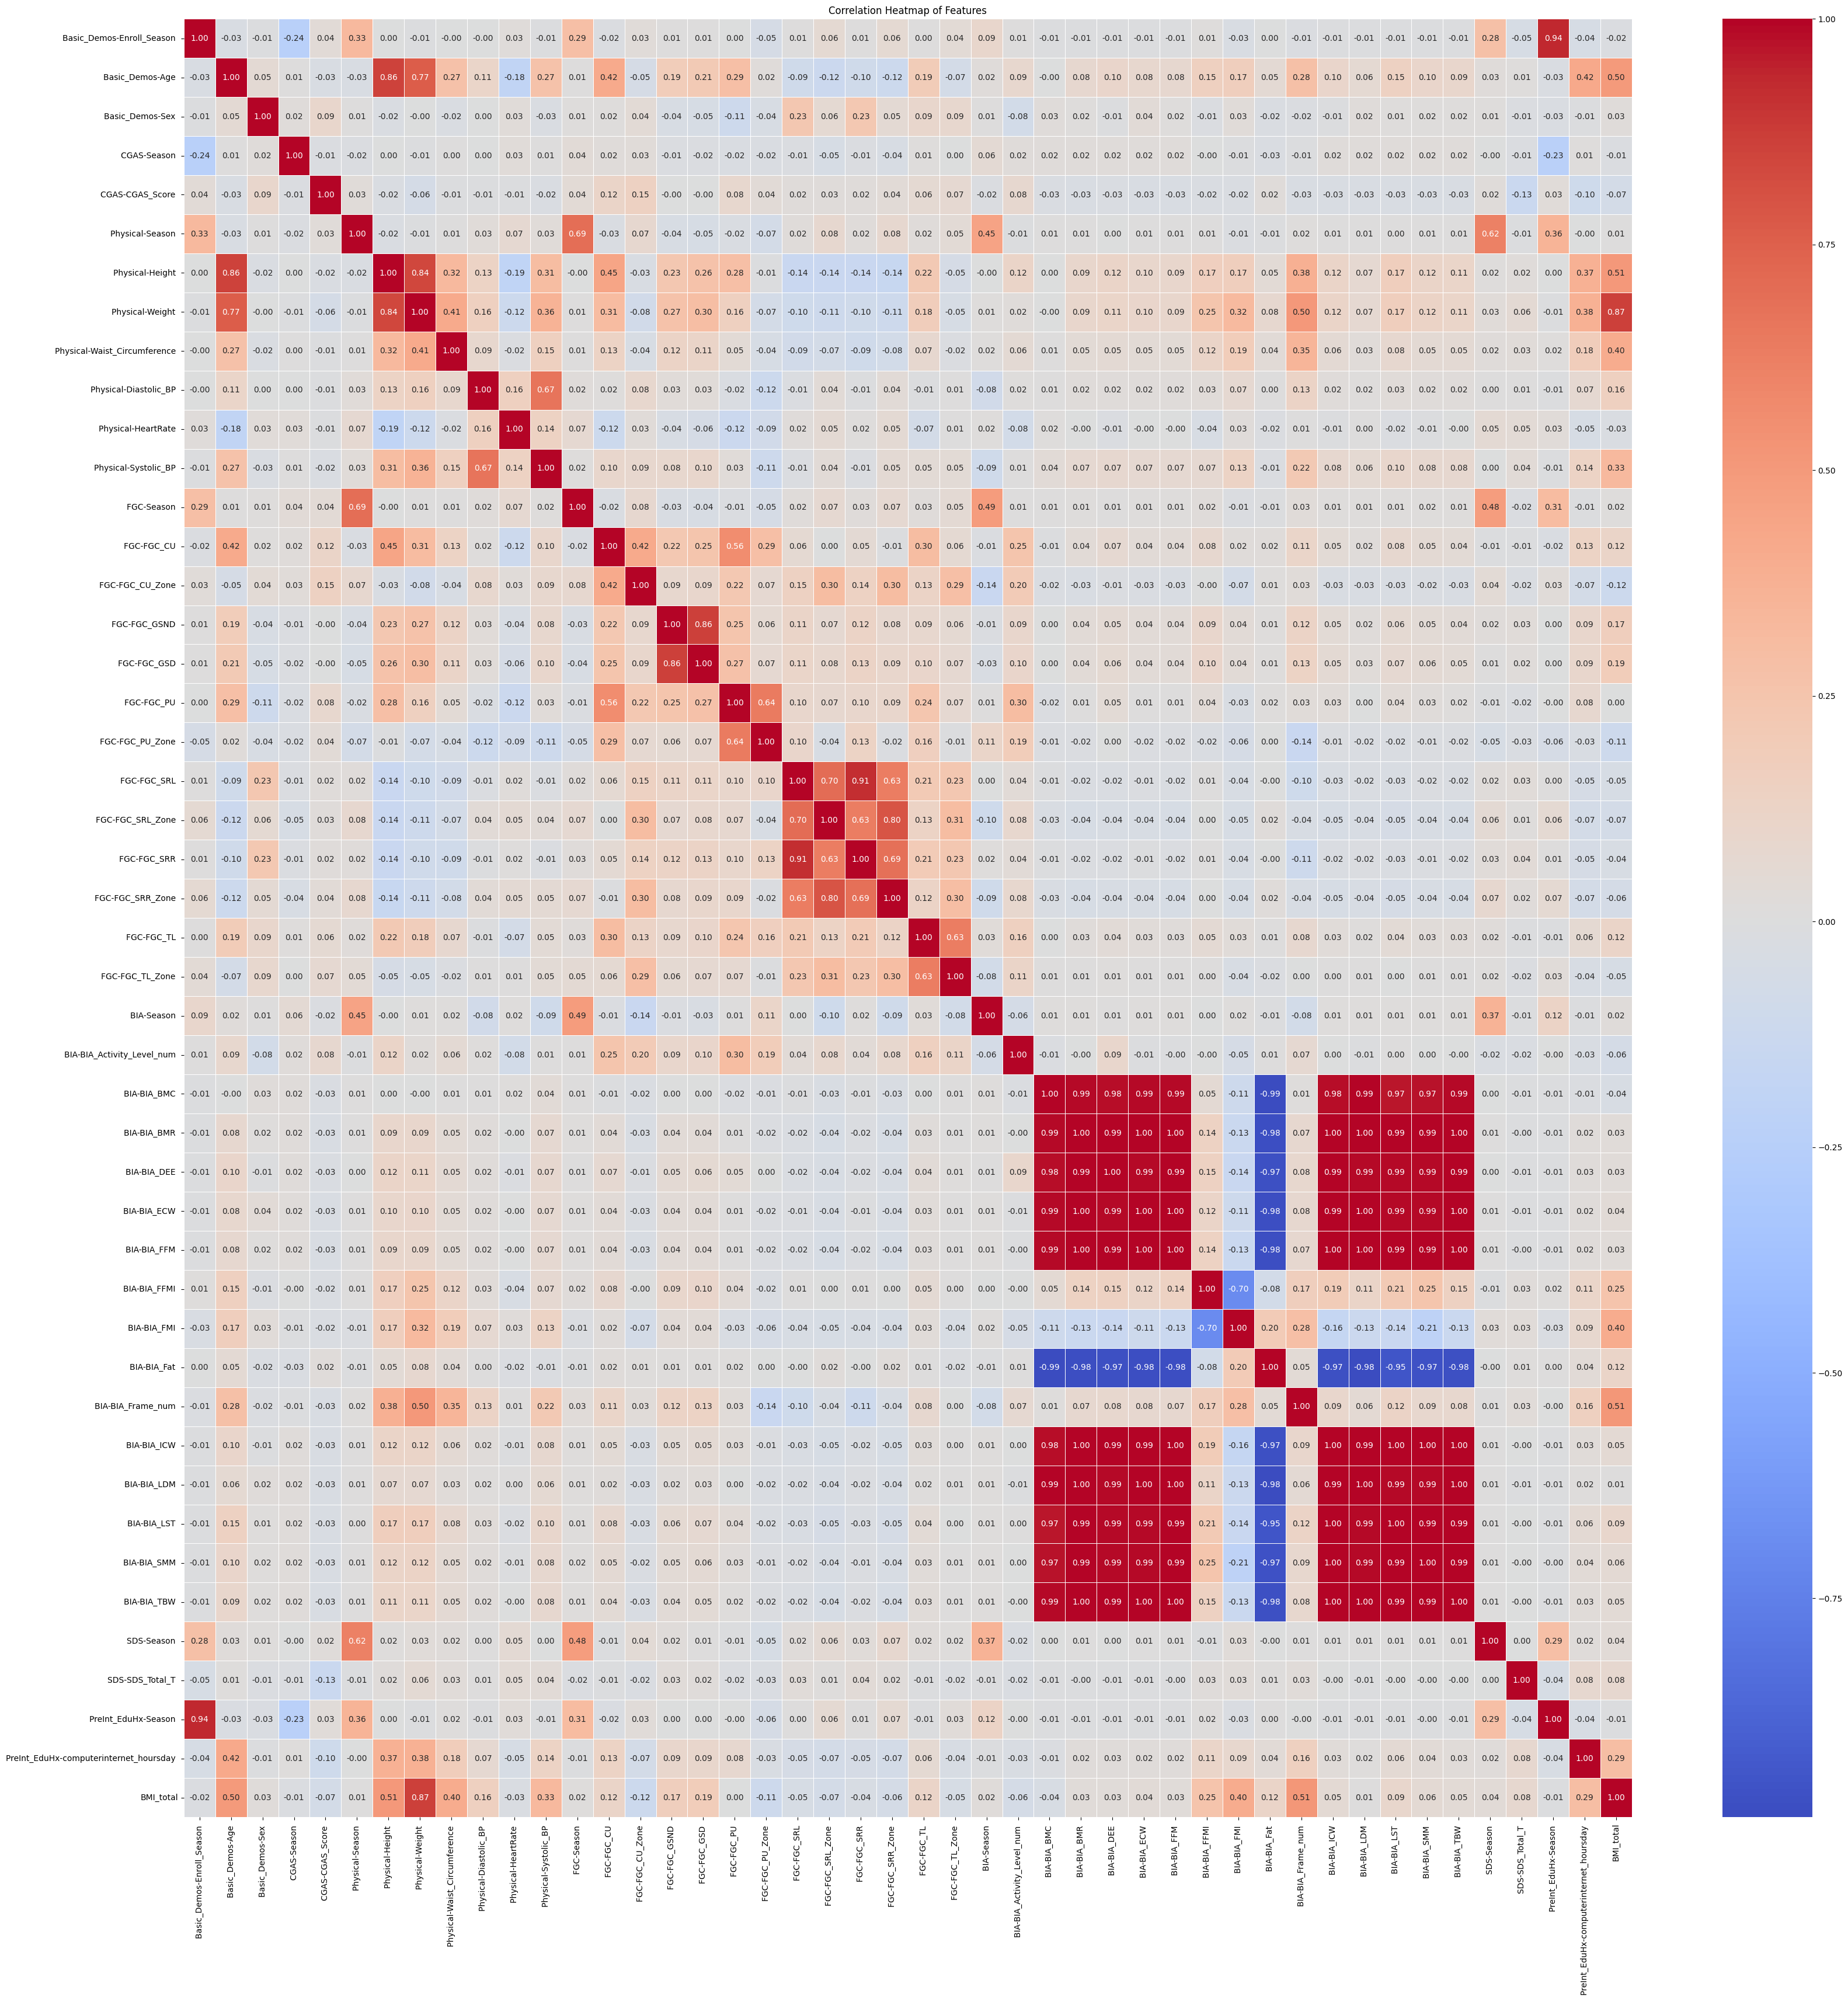

In [245]:
import seaborn as sns

# Calculate correlation matrix
corr_matrix = X.corr()

# Plot heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()


Feature 'Physical-Height ' è fortemente correlata con: ['Basic_Demos-Age '], eliminata.
Feature 'Physical-Weight ' è fortemente correlata con: ['Basic_Demos-Age '], eliminata.
Feature 'Physical-Systolic_BP ' è fortemente correlata con: ['Physical-Diastolic_BP '], eliminata.
Feature 'FGC-Season ' è fortemente correlata con: ['Physical-Season '], eliminata.
Feature 'FGC-FGC_GSD ' è fortemente correlata con: ['FGC-FGC_GSND '], eliminata.
Feature 'FGC-FGC_PU_Zone ' è fortemente correlata con: ['FGC-FGC_PU '], eliminata.
Feature 'FGC-FGC_SRL_Zone ' è fortemente correlata con: ['FGC-FGC_SRL '], eliminata.
Feature 'FGC-FGC_SRR ' è fortemente correlata con: ['FGC-FGC_SRL '], eliminata.
Feature 'FGC-FGC_SRR_Zone ' è fortemente correlata con: ['FGC-FGC_SRL '], eliminata.
Feature 'FGC-FGC_TL_Zone ' è fortemente correlata con: ['FGC-FGC_TL '], eliminata.
Feature 'BIA-BIA_BMR ' è fortemente correlata con: ['BIA-BIA_BMC '], eliminata.
Feature 'BIA-BIA_DEE ' è fortemente correlata con: ['BIA-BIA_BMC 

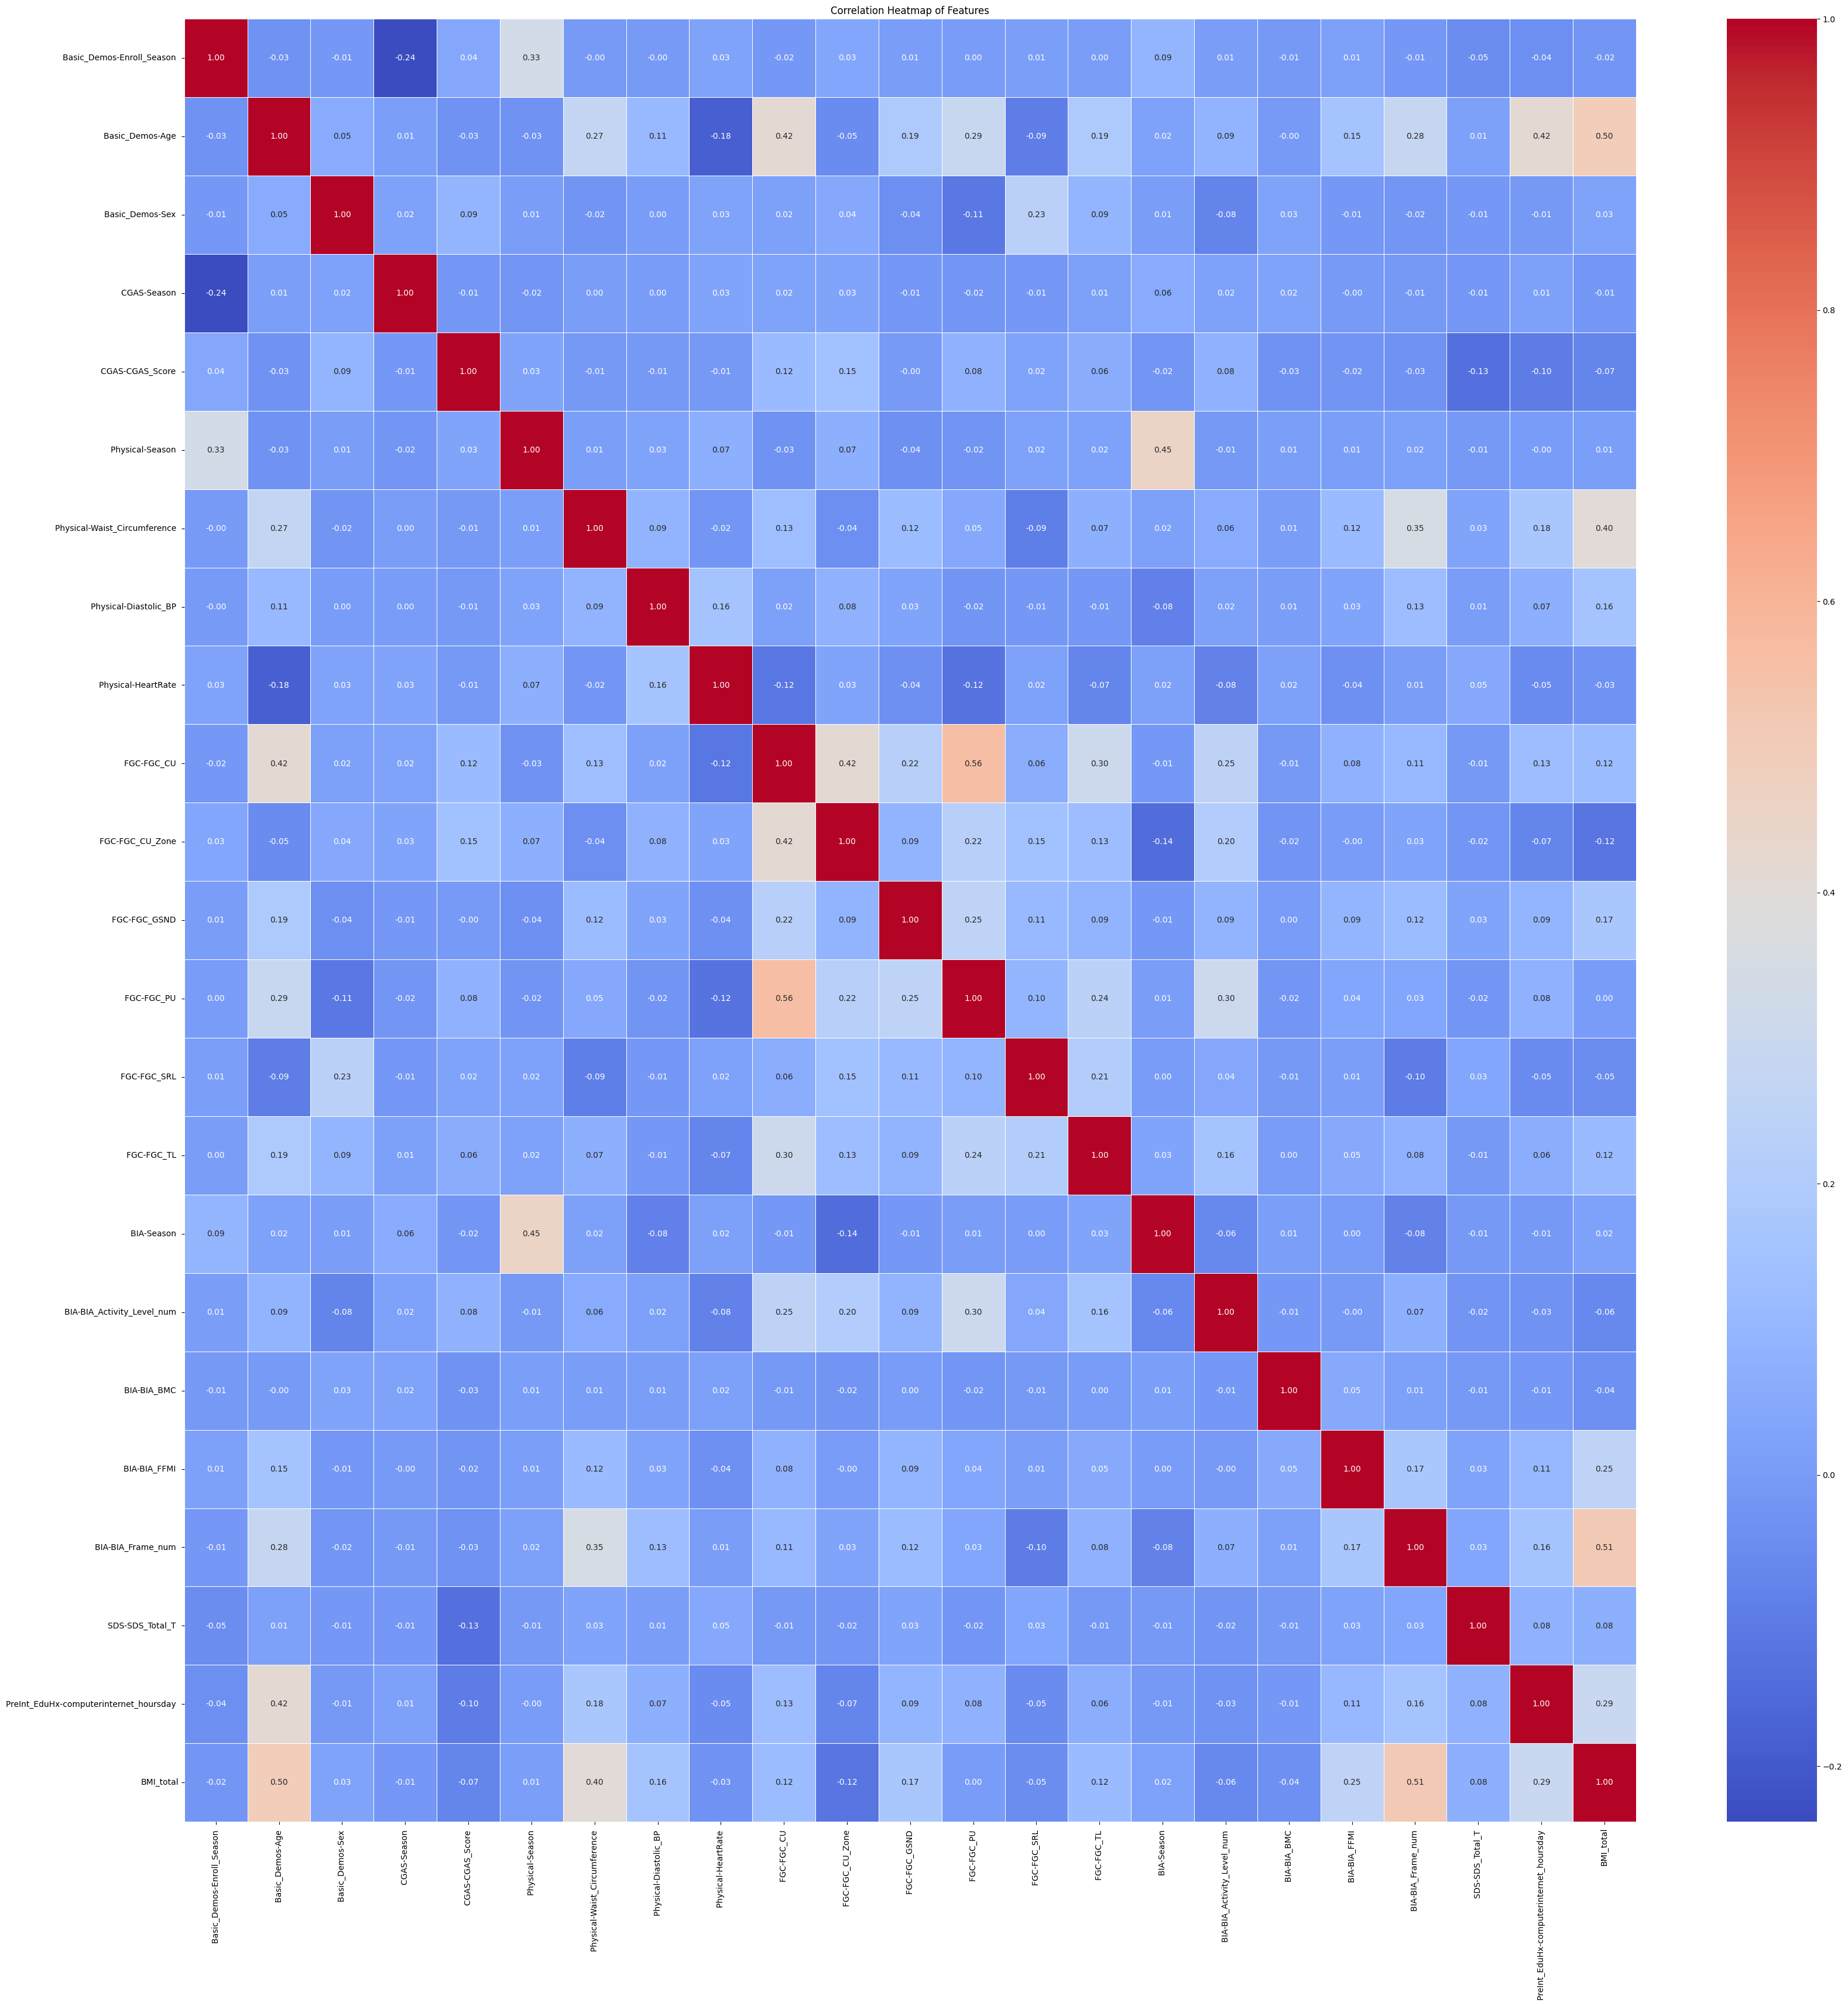

In [246]:
# Droppiamo le feature con una correlazione > di 0.7 o < di -0.7 -> Troppo correlate tra loro
import pandas as pd

threshold = 0.6

while True:
    corr_matrix = X.corr()  # Ricalcola la matrice di correlazione
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))  # Mantieni solo la parte superiore

    to_drop = None
    for column in upper.columns:
        if any(abs(upper[column]) >= threshold):
            to_drop = column
            break  # Esci dal ciclo appena trovi una feature da eliminare

    if to_drop is None:
        break  # Se non ci sono più feature da eliminare, esci dal ciclo

    correlated_features = upper.index[abs(upper[to_drop]) >= threshold].tolist()
    print(f"Feature '{to_drop}' è fortemente correlata con: {correlated_features}, eliminata.")

    X = X.drop(columns=to_drop)  # Elimina la feature dal dataset

print(f"Dropped features: {to_drop}")
X.shape


import seaborn as sns

# Riguardiamo la matrice di correlazione
corr_matrix = X.corr()

# Plot heatmap
plt.figure(figsize=(40, 40))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Features")
plt.show()

In [247]:
# memorizziamo le colonne che hanno rispettato tutti i criteri fino ad ora
# controlliamo che non ci siano valori nulli
columnsOfInterest = X.columns
nan_counts = X.loc[:, columnsOfInterest].isna().sum()
nan_counts

Basic_Demos-Enroll_Season                  0
Basic_Demos-Age                            0
Basic_Demos-Sex                            0
CGAS-Season                                0
CGAS-CGAS_Score                            0
Physical-Season                            0
Physical-Waist_Circumference               0
Physical-Diastolic_BP                      0
Physical-HeartRate                         0
FGC-FGC_CU                                 0
FGC-FGC_CU_Zone                            0
FGC-FGC_GSND                               0
FGC-FGC_PU                                 0
FGC-FGC_SRL                                0
FGC-FGC_TL                                 0
BIA-Season                                 0
BIA-BIA_Activity_Level_num                 0
BIA-BIA_BMC                                0
BIA-BIA_FFMI                               0
BIA-BIA_Frame_num                          0
SDS-SDS_Total_T                            0
PreInt_EduHx-computerinternet_hoursday     0
BMI_total 

In [248]:
print("X shape", X.shape)

y = df.loc[:, 'sii']
print("y shape", y.shape)

# Contiamo quanti valori ci sono per ogni classe
# in questo modo capiamo qual è la soglia minima
# predicendo sempre la classe più frequente
print(y.value_counts(normalize=True))


from sklearn.model_selection import train_test_split

X_train80, X_test20, y_train80, y_test20 = train_test_split(X, y, test_size=0.20, random_state=42)



X shape (2684, 23)
y shape (2684,)
sii
0.0    0.581222
1.0    0.267511
2.0    0.138599
3.0    0.012668
Name: proportion, dtype: float64


In [249]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Proviamo con un albero di decisione con tutti i parametri di default

decTree = DecisionTreeClassifier(random_state=42)
decTree.fit(X_train80,y_train80)

print("Train acc:", accuracy_score(y_true = y_train80, y_pred = decTree.predict(X_train80))) # -> overfitting!
print("Test acc:", accuracy_score(y_true = y_test20,  y_pred = decTree.predict(X_test20)))

from sklearn.model_selection import cross_val_score

scores = cross_val_score(decTree, X_train80, y_train80, cv=10)
print("Accuracy media con cv=20:", scores.mean())

Train acc: 1.0
Test acc: 0.4823091247672253
Accuracy media con cv=20: 0.4974570745490111


In [250]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

#
# Modello usando un albero di decisione
# usando come stopping criteria il numero di foglie
# split: 80/20
#

best_leaves = None
best_cv_acc = 0
for max_leaves in range(2,50):
    decTree = DecisionTreeClassifier(max_leaf_nodes=max_leaves, random_state=42)

    cv_scores = cross_val_score(decTree, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    # Save the best max_leaf_nodes
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        best_leaves = max_leaves

print(f"Il miglior numero di foglie è {best_leaves} con una cross-validation accuracy di {best_cv_acc:.3f}")

Il miglior numero di foglie è 5 con una cross-validation accuracy di 0.608


In [251]:
#
# Modello usando un albero di decisione
# usando come stopping criteria la profondità
# split: 80/20
#

bestDepth = None
best_cv_acc = 0

for max_depth in range(1, 20):
    decTree = DecisionTreeClassifier(max_depth=max_depth, random_state=42)
    cv_scores = cross_val_score(decTree, X_train80, y_train80, cv=20, scoring='accuracy')
    mean_cv_acc = np.mean(cv_scores)
    
    if mean_cv_acc > best_cv_acc:
        best_cv_acc = mean_cv_acc
        bestDepth = max_depth

print(f"Il miglior numero di profondità è {bestDepth} con una cross-validation accuracy di {best_cv_acc:.3f}")


Il miglior numero di profondità è 3 con una cross-validation accuracy di 0.607


In [252]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
import numpy as np
from scipy.stats import randint

#
# Tuning dei parametri
# Iniziamo con una RandomizedSearchCV
# 

param_dist = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, 20, 30, 40, 50, 60, 70],
    'min_samples_split': [2, 5, 10, 15, 20, 25, 30, 50, 70, 90],
    'min_samples_leaf': [1, 5, 10, 15, 20, 25, 30, 50, 70, 90],
    'max_features': [None, 'sqrt', 'log2'],
    # 'min_weight_fraction_leaf': [0.0, 0.05, 
    #                              0.1, 0.15, 
    #                              0.2,],
}

tree = DecisionTreeClassifier(random_state=42)
random_search = RandomizedSearchCV(estimator=tree, param_distributions=param_dist, 
                                   n_iter=500, cv=20, scoring="accuracy", random_state=42, n_jobs=-1)
random_search.fit(X_train80, y_train80)

best_params_random = random_search.best_params_
print("Best parameters:", best_params_random)


Best parameters: {'min_samples_split': 50, 'min_samples_leaf': 90, 'max_features': None, 'max_depth': 50, 'criterion': 'entropy'}


In [253]:
print(random_search.best_estimator_)
best_tree = random_search.best_estimator_
best_tree.fit(X_train80, y_train80)

train_acc = accuracy_score(y_true=y_train80, y_pred=best_tree.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=best_tree.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(best_tree, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = best_tree.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print("Top features based on importance:")
print(importance_df.head(10))

DecisionTreeClassifier(criterion='entropy', max_depth=50, min_samples_leaf=90,
                       min_samples_split=50, random_state=42)
Train Accuracy: 0.619
Test Accuracy: 0.598
Cross-Validation Accuracy: 0.6120 ± 0.0283
Top features based on importance:
Basic_Demos-Age                            0.459423
PreInt_EduHx-computerinternet_hoursday     0.223494
SDS-SDS_Total_T                            0.168369
FGC-FGC_GSND                               0.036867
FGC-FGC_PU                                 0.031607
FGC-FGC_CU                                 0.028710
BIA-BIA_BMC                                0.018553
BIA-BIA_FFMI                               0.017842
BMI_total                                  0.015135
Physical-Waist_Circumference               0.000000
dtype: float64


In [254]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'criterion': ['entropy'],  # Keep the best criterion from RandomizedSearchCV
    'max_depth': [None, 45, 50, 55, 65],  # Try specific depths around the best one
    'min_samples_split': [40, 45, 50, 55, 60],  # Keep narrow for now
    'min_samples_leaf': [80, 85, 90, 105, 100],  # Try specific leaf sizes
    'max_features': [None],  # Keep exploring common values
    # 'min_weight_fraction_leaf': [0.03, 0.04, 0.05, 0.06, 0.07]
}

tree = DecisionTreeClassifier(random_state=42)
grid_search = GridSearchCV(estimator=tree, param_grid=param_grid, cv=20, scoring="accuracy", n_jobs=-1)
from sklearn.utils.class_weight import compute_sample_weight

# Compute weights based on class distribution
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train80)
grid_search.fit(X_train80, y_train80, sample_weight=sample_weights)

print("Best parameters:", grid_search.best_params_)

Best parameters: {'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 100, 'min_samples_split': 40}


In [255]:
print(grid_search.best_estimator_)
best_tree = grid_search.best_estimator_
best_tree.fit(X_train80, y_train80)

train_acc = accuracy_score(y_true=y_train80, y_pred=best_tree.predict(X_train80))
test_acc = accuracy_score(y_true=y_test20, y_pred=best_tree.predict(X_test20))
print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

scores = cross_val_score(best_tree, X_train80, y_train80, cv=20, scoring='accuracy')
print(f"Cross-Validation Accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

feature_importances = best_tree.feature_importances_
importance_df = pd.Series(feature_importances, index=X_train80.columns).sort_values(ascending=False)

print("Top features based on importance:")
print(importance_df.head(10))  

DecisionTreeClassifier(criterion='entropy', min_samples_leaf=100,
                       min_samples_split=40, random_state=42)
Train Accuracy: 0.619
Test Accuracy: 0.598
Cross-Validation Accuracy: 0.6180 ± 0.0271
Top features based on importance:
Basic_Demos-Age                            0.470330
PreInt_EduHx-computerinternet_hoursday     0.228052
SDS-SDS_Total_T                            0.152962
FGC-FGC_GSND                               0.037618
BMI_total                                  0.034319
FGC-FGC_PU                                 0.032251
FGC-FGC_CU                                 0.025535
BIA-BIA_BMC                                0.018931
Physical-Season                            0.000000
Physical-Waist_Circumference               0.000000
dtype: float64


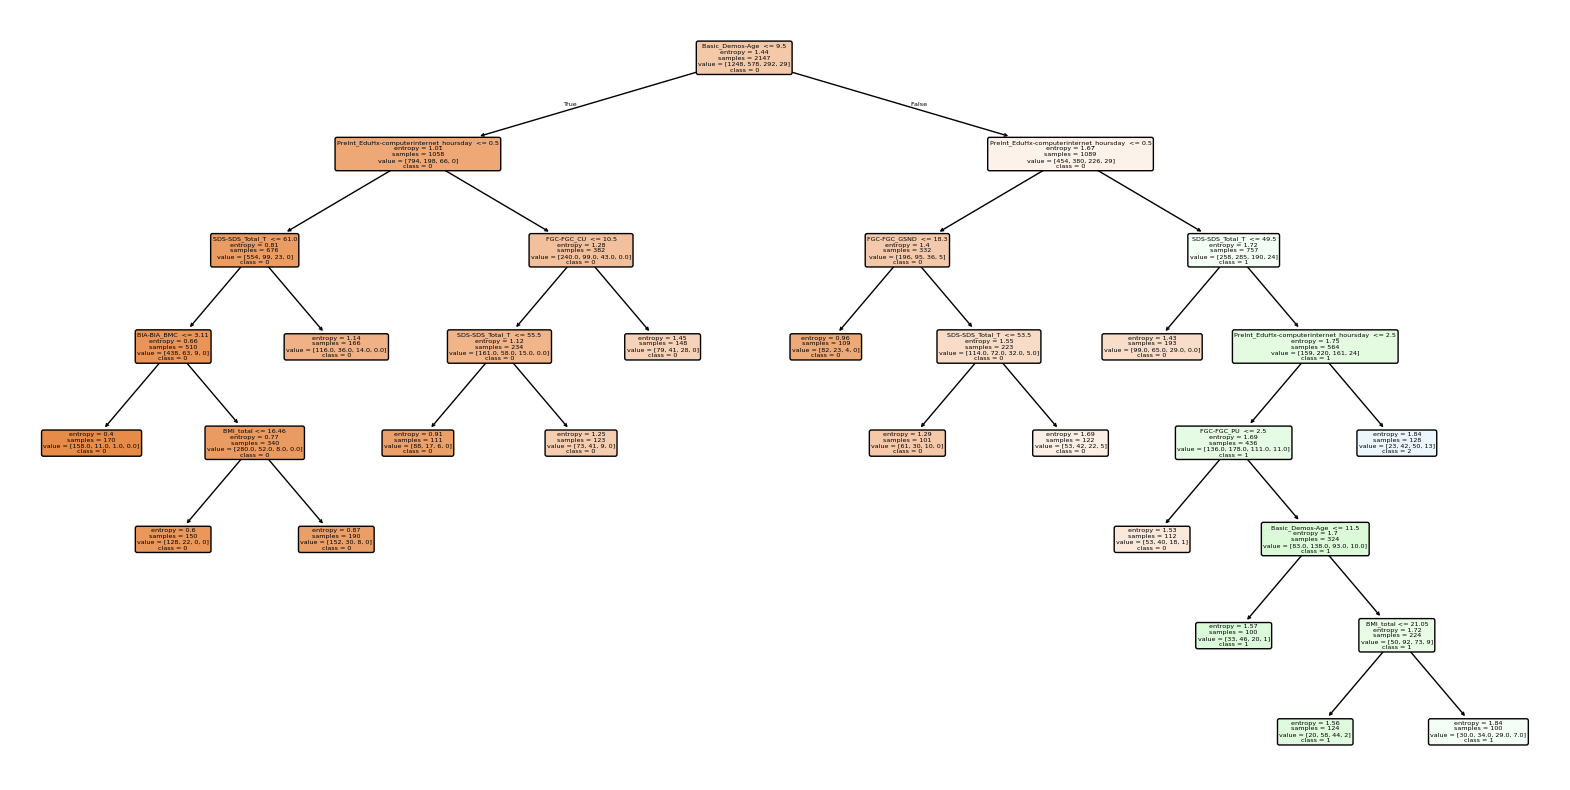

In [256]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10)) 
plot_tree(best_tree, filled=True, feature_names=X_train80.columns, class_names=["0", "1", "2", "3"], 
          rounded=True, proportion=False, precision=2)
plt.show()


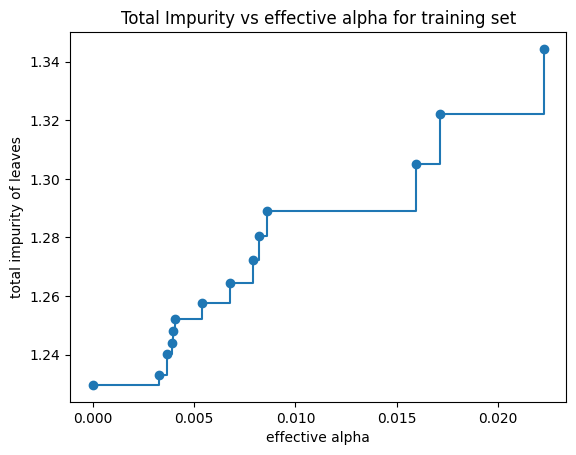

In [257]:
import matplotlib.pyplot as plt

#
# Proviamo a fare pruning usando cross-validation
# Split: 80/20
#

path = best_tree.cost_complexity_pruning_path(X_train80, y_train80)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

fig, ax = plt.subplots()
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Total Impurity vs effective alpha for training set");

#
# Alpha vicino a 0.002 -> sembra essere un buon valore
#

In [258]:
# Costruiamo tutti gli alberi con i vari valori di ccp_alpha
ccp_alphas = ccp_alphas[:-1]
dts = []
best_params_grid = grid_search.best_params_
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ccp_alpha,
        **best_params_grid
    )
    dt.fit(X_train80, y_train80)
    dts.append(dt)

    test_acc = accuracy_score(y_true=y_test20, y_pred=dt.predict(X_test20))

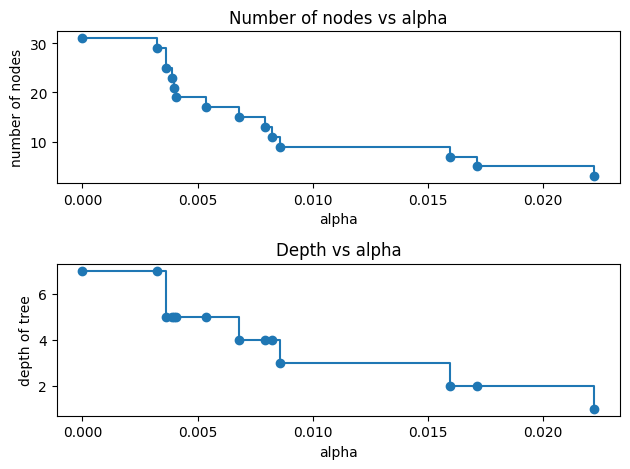

In [259]:
node_counts = [dt.tree_.node_count for dt in dts]
depth = [dt.tree_.max_depth for dt in dts]
fig, ax = plt.subplots(2, 1)
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("alpha")
ax[0].set_ylabel("number of nodes")
ax[0].set_title("Number of nodes vs alpha")
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("alpha")
ax[1].set_ylabel("depth of tree")
ax[1].set_title("Depth vs alpha")
fig.tight_layout()

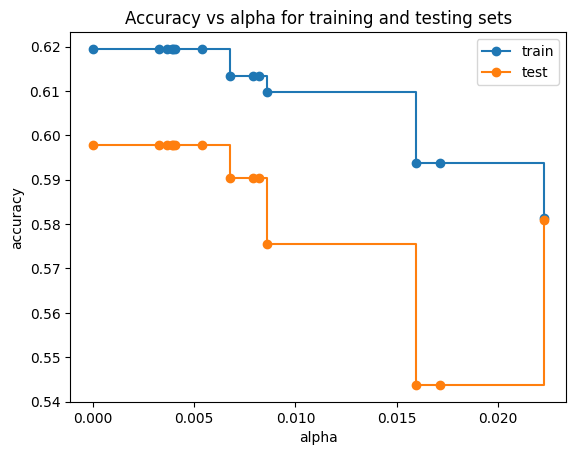

In [260]:
train_scores = [dt.score(X_train80, y_train80) for dt in dts]
test_scores = [dt.score(X_test20, y_test20) for dt in dts]

fig, ax = plt.subplots()
ax.set_xlabel("alpha")
ax.set_ylabel("accuracy")
ax.set_title("Accuracy vs alpha for training and testing sets")
ax.plot(ccp_alphas, train_scores, marker="o", label="train", drawstyle="steps-post")
ax.plot(ccp_alphas, test_scores, marker="o", label="test", drawstyle="steps-post")
ax.legend()
plt.show()

<Axes: xlabel='alpha'>

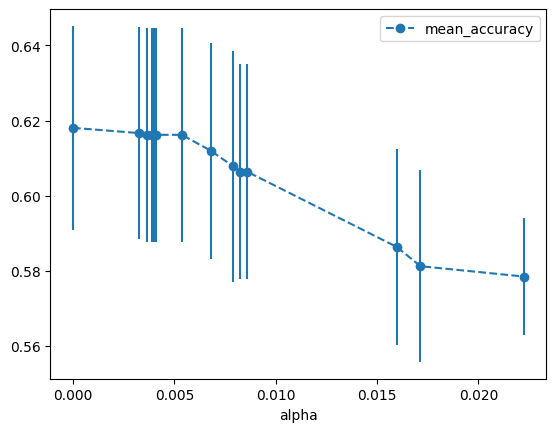

In [261]:
# Controlliamo i valori di alpha per vedere quale è più "consistente" nei dati
# vale a dire, quale valore di alpha ha la media più alta
alpha_loop_values = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ccp_alpha,
        **best_params_grid
    )
    scores = cross_val_score(dt, X_train80, y_train80, cv=20)
    alpha_loop_values.append([ccp_alpha, np.mean(scores), np.std(scores)])

alpha_results = pd.DataFrame(alpha_loop_values, columns=['alpha', 'mean_accuracy', 'std'])

alpha_results.plot(x='alpha', 
                   y='mean_accuracy', 
                   yerr='std', 
                   marker='o', 
                   linestyle='--')

In [262]:
# prendo il valore effettivo di alpha che ha la media più alta
subset = alpha_results[(alpha_results['alpha'] >= 0.0) 
              & (alpha_results['alpha'] < 0.010)]

ideal_alpha = subset.loc[subset['mean_accuracy'].idxmax(), 'alpha']
ideal_alpha = float(ideal_alpha)
print("Miglior valore di alpha:", ideal_alpha)

Miglior valore di alpha: 0.0


In [263]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

#
# Creo il modello con il valore di alpha ideale
# Split: 80/20
# Mostro la CM per vedere la distribuzione dei valori predetti
#

dt_pruned = DecisionTreeClassifier(
        random_state=42, 
        ccp_alpha=ideal_alpha,
        **best_params_grid
    )
dt_pruned.fit(X_train80, y_train80)
print("Train accuracy:", accuracy_score(y_true=y_train80, y_pred=dt_pruned.predict(X_train80)))
print("Test accuracy:", accuracy_score(y_true=y_test20, y_pred=dt_pruned.predict(X_test20)))

cv_scores = cross_val_score(dt_pruned, X_train80, y_train80, cv=20, scoring="accuracy")

print(f"Cross-Validation Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Train accuracy: 0.6194690265486725
Test accuracy: 0.5977653631284916
Cross-Validation Accuracy: 0.6180 ± 0.0271


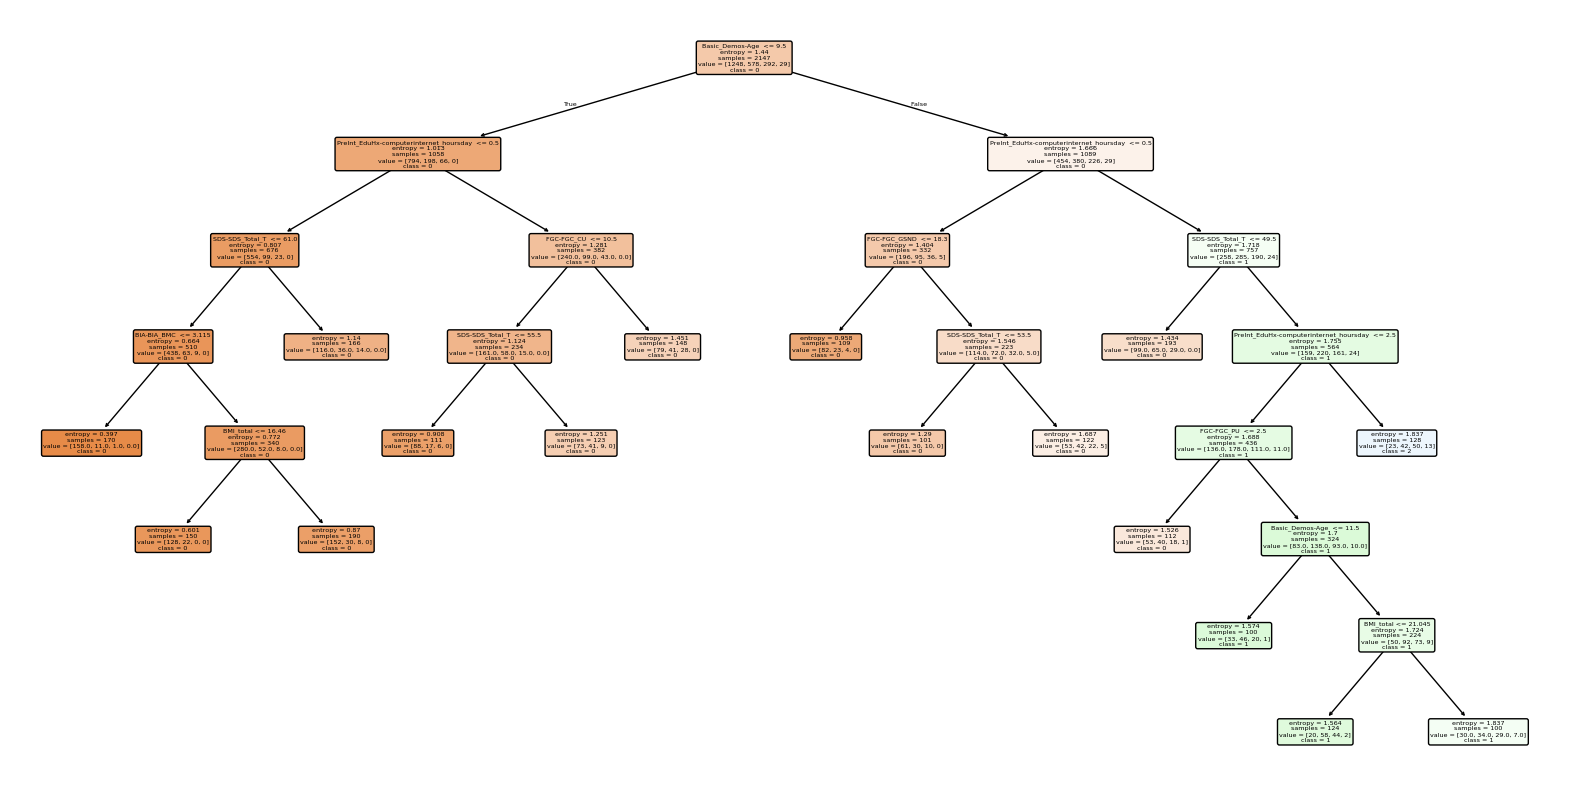

In [264]:
from sklearn.tree import plot_tree

#
# Mostro l'albero di decisione che si va' a crearea usando il valore di alpha ideale
#

plt.figure(figsize=(20,10))
plot_tree(dt_pruned, filled=True, rounded=True, feature_names=X.columns, class_names=["0", "1", "2", "3"])
plt.show()

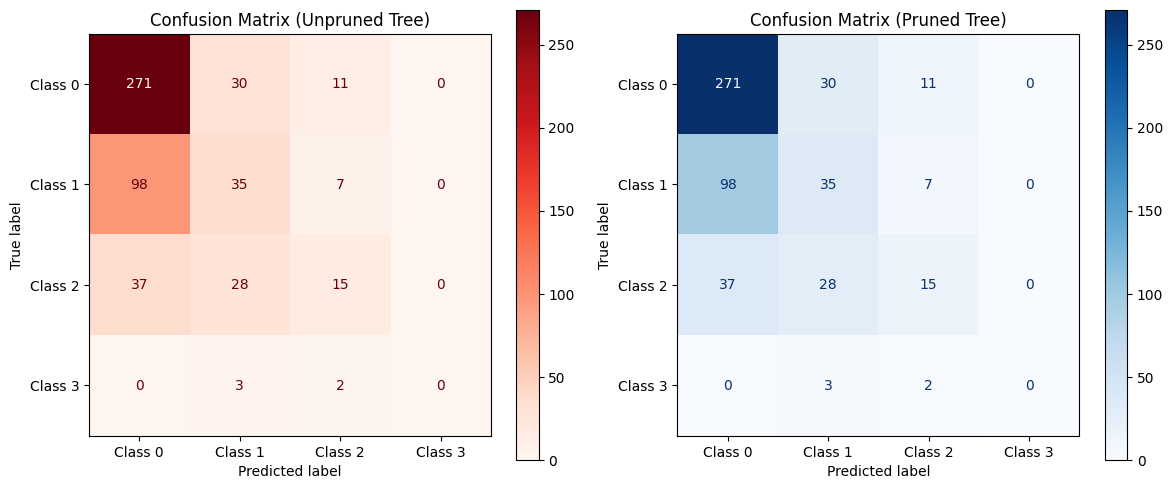

In [265]:
# Mostra la matrice di confusione con etichette
cm_unpruned = confusion_matrix(y_test20, best_tree.predict(X_test20))
cm_pruned = confusion_matrix(y_test20, dt_pruned.predict(X_test20))

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Unpruned tree confusion matrix
disp_unpruned = ConfusionMatrixDisplay(confusion_matrix=cm_unpruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_unpruned.plot(ax=axes[0], cmap="Reds")
axes[0].set_title("Confusion Matrix (Unpruned Tree)")

# Pruned tree confusion matrix
disp_pruned = ConfusionMatrixDisplay(confusion_matrix=cm_pruned, display_labels=["Class 0", "Class 1", "Class 2", "Class 3"])
disp_pruned.plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Confusion Matrix (Pruned Tree)")

# Adjust layout
plt.tight_layout()
plt.show()

In [266]:
from sklearn.metrics import classification_report

# Predictions for both trees
y_pred_unpruned = best_tree.predict(X_test20)
y_pred_pruned = dt_pruned.predict(X_test20)

# Generate classification reports
report_unpruned = classification_report(y_test20, y_pred_unpruned, target_names=["Class 0", "Class 1", "Class 2", "Class 3"])
report_pruned = classification_report(y_test20, y_pred_pruned, target_names=["Class 0", "Class 1", "Class 2", "Class 3"])

print("=== Classification Report: Unpruned Tree ===")
print(report_unpruned)

print("\n=== Classification Report: Pruned Tree ===")
print(report_pruned)


=== Classification Report: Unpruned Tree ===
              precision    recall  f1-score   support

     Class 0       0.67      0.87      0.75       312
     Class 1       0.36      0.25      0.30       140
     Class 2       0.43      0.19      0.26        80
     Class 3       0.00      0.00      0.00         5

    accuracy                           0.60       537
   macro avg       0.37      0.33      0.33       537
weighted avg       0.55      0.60      0.55       537


=== Classification Report: Pruned Tree ===
              precision    recall  f1-score   support

     Class 0       0.67      0.87      0.75       312
     Class 1       0.36      0.25      0.30       140
     Class 2       0.43      0.19      0.26        80
     Class 3       0.00      0.00      0.00         5

    accuracy                           0.60       537
   macro avg       0.37      0.33      0.33       537
weighted avg       0.55      0.60      0.55       537



C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()

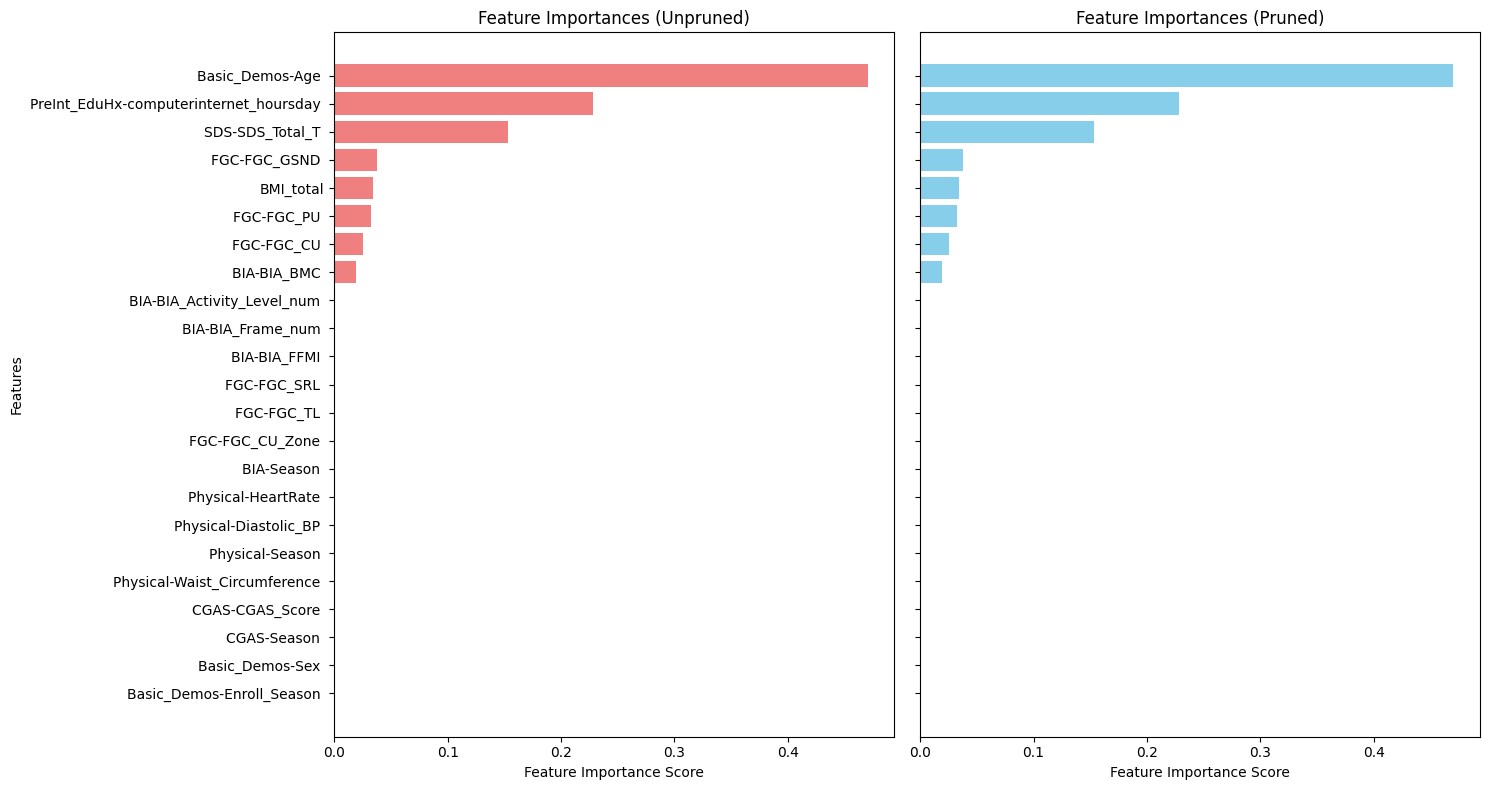

In [267]:
import numpy as np
import matplotlib.pyplot as plt

# Feature importances for both trees
importances_unpruned = best_tree.feature_importances_
importances_pruned = dt_pruned.feature_importances_

# Sort feature importances
sorted_idx_unpruned = np.argsort(importances_unpruned)[::-1]
sorted_idx_pruned = np.argsort(importances_pruned)[::-1]

sorted_features_unpruned = X_train80.columns[sorted_idx_unpruned]
sorted_features_pruned = X_train80.columns[sorted_idx_pruned]

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)

# Unpruned tree plot
axes[0].barh(sorted_features_unpruned, importances_unpruned[sorted_idx_unpruned], color='lightcoral')
axes[0].set_xlabel("Feature Importance Score")
axes[0].set_ylabel("Features")
axes[0].set_title("Feature Importances (Unpruned)")
axes[0].invert_yaxis()

# Pruned tree plot
axes[1].barh(sorted_features_pruned, importances_pruned[sorted_idx_pruned], color='skyblue')
axes[1].set_xlabel("Feature Importance Score")
axes[1].set_title("Feature Importances (Pruned)")

# Show the combined plot
plt.tight_layout()
plt.show()


In [279]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold

min_features_to_select = 1  # Minimum number of features to consider
cv = StratifiedKFold(20)

rfecv = RFECV(
    estimator=best_tree,
    step=1,
    cv=cv,
    scoring="accuracy",
    min_features_to_select=min_features_to_select,
    n_jobs=2,
)
rfecv.fit(X_train80, y_train80)

print(f"Optimal number of features: {rfecv.n_features_}")

Optimal number of features: 8


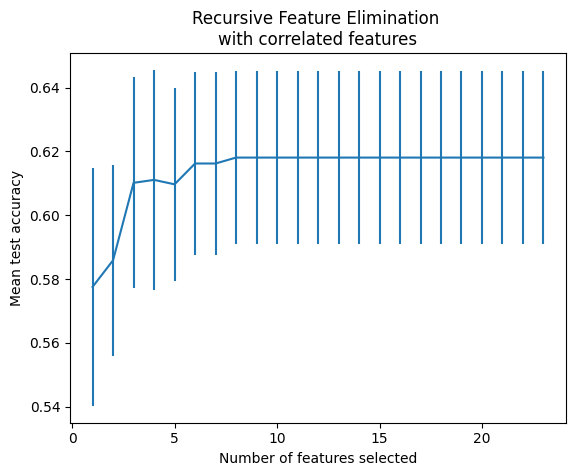

In [280]:
import matplotlib.pyplot as plt
import pandas as pd

cv_results = pd.DataFrame(rfecv.cv_results_)
plt.figure()
plt.xlabel("Number of features selected")
plt.ylabel("Mean test accuracy")
plt.errorbar(
    x=cv_results["n_features"],
    y=cv_results["mean_test_score"],
    yerr=cv_results["std_test_score"],
)
plt.title("Recursive Feature Elimination \nwith correlated features")
plt.show()

In [282]:
selected_features = X.columns[rfecv.support_]
print("Feature selezionate:", list(selected_features))

X_train_rfecv = X_train80[selected_features]
X_test_rfecv = X_test20[selected_features]

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Creiamo un nuovo Decision Tree
best_tree_rfecv = DecisionTreeClassifier(
        **best_params_grid,
        random_state=42 )

# Addestriamo il modello con le feature selezionate
best_tree_rfecv.fit(X_train_rfecv, y_train80)

# Previsioni sul test set ridotto
y_pred_rfecv = best_tree_rfecv.predict(X_test_rfecv)

# Numero di fold per la cross-validation (es. 5)
cv_folds = 20

# Eseguiamo la cross-validation
cv_scores = cross_val_score(best_tree_rfecv, X_train_rfecv[selected_features], y_train80, cv=cv_folds, scoring='accuracy')

# Stampiamo il risultato medio e la deviazione standard
print(f"Accuratezza media con cross-validation: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Feature selezionate: ['Basic_Demos-Age ', 'FGC-FGC_CU ', 'FGC-FGC_GSND ', 'FGC-FGC_PU ', 'BIA-BIA_BMC ', 'SDS-SDS_Total_T ', 'PreInt_EduHx-computerinternet_hoursday ', 'BMI_total']
Accuratezza media con cross-validation: 0.6153 ± 0.0283


In [283]:
from sklearn.ensemble import BaggingClassifier

maxScore = -1
bestEstimators = -1
for i in range(1, 51):
   bagged_dt = BaggingClassifier(estimator=best_tree_rfecv, n_estimators=i, random_state=42)
   cv_scores = cross_val_score(bagged_dt, X_train_rfecv, y_train80, cv=5, scoring='accuracy')
   mean_cv_score = cv_scores.mean()  # Media dell'accuratezza nei fold
   
   if mean_cv_score > maxScore:
       maxScore = mean_cv_score
       bestEstimators = i

# Una volta trovato il migliore n_estimators, allena il modello finale
bestDt_bagging = BaggingClassifier(estimator=best_tree_rfecv, n_estimators=bestEstimators, random_state=42)
bestDt_bagging.fit(X_train_rfecv, y_train80)

print("bestEstimators:", bestEstimators)
print("Accuracy: {:.3f}".format(accuracy_score(y_true=y_test20, y_pred=bestDt_bagging.predict(X_test_rfecv))))

cv_scores = cross_val_score(bestDt_bagging, X_train_rfecv, y_train80, cv=20, scoring='accuracy')

print(f"Accuracy media: {cv_scores.mean()}")
print(f"Standard Deviation: {cv_scores.std()}")


bestEstimators: 18
Accuracy: 0.594
Accuracy media: 0.6040584977500865
Standard Deviation: 0.033334064560668016


Error/Bias/Variance at the last iteration: [0.66378026 0.61206238 0.05171788]


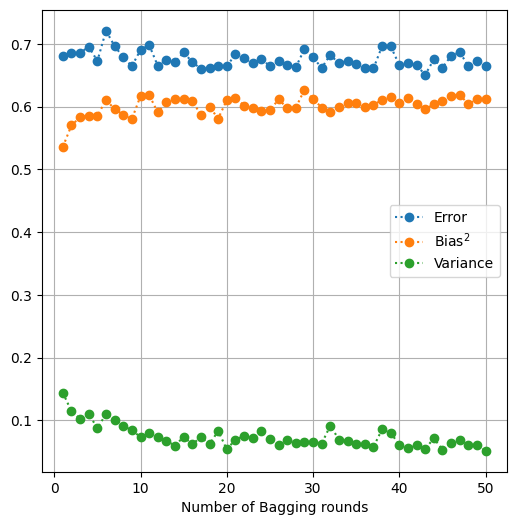

In [170]:
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

N_TESTS = 20
stats = np.array([])
bags = range(1,51)
for l in bags:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                max_depth=(best_params_grid['max_depth']),
                min_samples_split=int(best_params_grid['min_samples_split']),
                min_samples_leaf=int(best_params_grid['min_samples_leaf']),
                criterion=best_params_grid['criterion'],
                max_features=None, # best_params['max_features'],
                ccp_alpha=ideal_alpha,
                random_state=42
            )
        bagged_dt = BaggingClassifier(estimator=dt, n_estimators=l, random_state=42)
        bagged_dt.fit(Xs,ys)
        
        y_pred = bagged_dt.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20-np.mean(y_preds,axis=1))**2
    dt_variance = np.var(y_preds,axis=1)
    dt_error = (y_preds - y_test20.to_numpy().reshape(-1, 1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats

fig, ax = plt.subplots(figsize=(6,6))

ax.plot(bags,stats[0,:], 'o:', label='Error')
ax.plot(bags,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(bags,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Bagging rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [172]:
from sklearn.ensemble import AdaBoostClassifier

adaboost = AdaBoostClassifier(best_tree, n_estimators=10, random_state=42)

adaboost.fit(X_train80,y_train80)
print ("Accuracy:", accuracy_score(y_true=y_test20, y_pred=adaboost.predict(X_test20) ))

Accuracy: 0.47113594040968343


C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(
C:\Users\Utente\AppData\Roaming\Python\Python312\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. U

Error/Bias/Variance at the last iteration: [0.95074488 0.50443669 0.44630819]


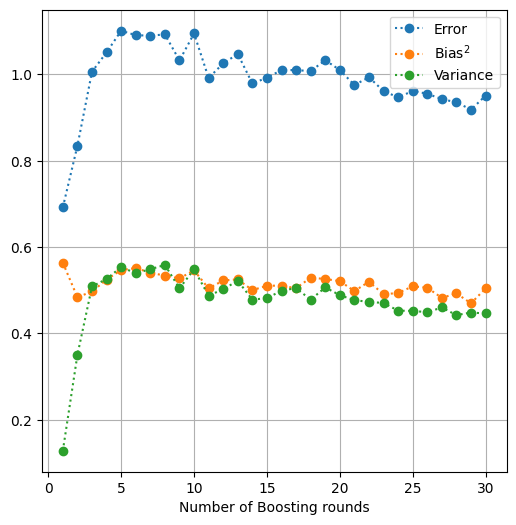

In [173]:
from sklearn.utils import resample
from sklearn.ensemble import AdaBoostClassifier

N_TESTS = 20
stats = np.array([])
boosts = range(1,31)
for l in boosts:
    y_preds = np.array([])
    
    for i in range(N_TESTS):
        Xs, ys = resample(X_train80, y_train80, n_samples=int(0.67*len(y_train80)) )

        # train a decision tree classifier
        dt = DecisionTreeClassifier(
                max_depth=(best_params_grid['max_depth']),
                min_samples_split=int(best_params_grid['min_samples_split']),
                min_samples_leaf=int(best_params_grid['min_samples_leaf']),
                criterion=best_params_grid['criterion'],
                max_features=None, # best_params['max_features'],
                ccp_alpha=ideal_alpha,
                random_state=42
            )
        adaboost = AdaBoostClassifier(estimator=dt, n_estimators=l, random_state=42)
        adaboost.fit(Xs,ys)
        
        y_pred = adaboost.predict(X_test20)
        y_preds = np.column_stack( [y_preds, y_pred] ) if y_preds.size else y_pred

    dt_bias     = (y_test20 - np.mean(y_preds, axis=1))**2
    dt_variance = np.var(y_preds, axis=1)
    dt_error    = (y_preds - y_test20.to_numpy().reshape(-1,1))**2

    run_stats = np.array([dt_error.mean(), dt_bias.mean(), dt_variance.mean()])
    
    stats = np.column_stack( [stats, run_stats]) if stats.size else run_stats
    
fig, ax = plt.subplots(figsize=(6,6))

ax.plot(boosts,stats[0,:], 'o:', label='Error')
ax.plot(boosts,stats[1,:], 'o:', label='Bias$^2$')
ax.plot(boosts,stats[2,:], 'o:', label='Variance')
ax.set_xlabel('Number of Boosting rounds')
ax.grid()
ax.legend()

print ("Error/Bias/Variance at the last iteration:", stats[:,-1])

In [174]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train80, y_train80)
accuracy_rf = accuracy_score(y_test20, rf.predict(X_test20))

print(f"Random Forest - Test Accuracy: {accuracy_rf:.3f}")


Random Forest - Test Accuracy: 0.581


In [177]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [50, 100, 150, 200, 250, 300, 400, 500, 750, 1000],
    'max_depth': [None, 5, 10, 15, 20, 30, 50],
    'min_samples_split': [2, 5, 10, 15, 20, 30, 50],
    'min_samples_leaf': [1, 5, 10, 15, 20, 30, 50],
    'max_features': [None, 'sqrt', 'log2']
}

rf = RandomForestClassifier(random_state=42)
Random_search = RandomizedSearchCV(estimator=rf, param_distributions=param_grid, 
                                   n_iter=100, cv=5, n_jobs=-1, verbose=0, random_state=42, error_score='raise')
Random_search.fit(X_train80, y_train80)

print("Best Parameters:", Random_search.best_params_)


Best Parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 15, 'max_features': None, 'max_depth': 5}


In [179]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

best_rf_params = Random_search.best_params_
param_grid = {
    'max_depth': range(max(1, best_rf_params['max_depth']-2), best_rf_params['max_depth']+2),
    'min_samples_split': range(max(2, best_rf_params['min_samples_split']-2), best_rf_params['min_samples_split']+2),
    'min_samples_leaf': range(max(1, best_rf_params['min_samples_leaf']-2), best_rf_params['min_samples_leaf']+2),
    'max_features': [best_rf_params['max_features']],
    'n_estimators': [best_rf_params['n_estimators']-20, best_rf_params['n_estimators']-10,
                     best_rf_params['n_estimators'],
                     best_rf_params['n_estimators']+10, best_rf_params['n_estimators']-20]
            }

rf = RandomForestClassifier(random_state=42)
Grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, 
                           cv=5, n_jobs=-1, verbose=0, scoring='accuracy')
Grid_search.fit(X_train80, y_train80)

print("Best Parameters from Grid Search:", Grid_search.best_params_)

best_grid_rf = Grid_search.best_estimator_
test_accuracy = accuracy_score(y_test20, best_grid_rf.predict(X_test20))
print(f"Random Forest - Test Accuracy (after Grid Search): {test_accuracy:.3f}")


Best Parameters from Grid Search: {'max_depth': 3, 'max_features': None, 'min_samples_leaf': 14, 'min_samples_split': 2, 'n_estimators': 300}
Random Forest - Test Accuracy (after Grid Search): 0.588


In [180]:
# Ottieni l'importanza delle feature
importances = best_grid_rf.feature_importances_

# Creiamo un DataFrame per ordinare le feature in base all'importanza
feature_importance_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Stampa le feature più importanti
print(feature_importance_df)

                                    Feature  Importance
1                          Basic_Demos-Age     0.516267
21  PreInt_EduHx-computerinternet_hoursday     0.203476
20                       SDS-SDS_Total_Raw     0.152037
9                               FGC-FGC_CU     0.043496
11                            FGC-FGC_GSND     0.018386
14                              FGC-FGC_TL     0.015679
8                       Physical-HeartRate     0.011933
17                             BIA-BIA_BMC     0.010164
22                                BMI_total    0.007554
12                              FGC-FGC_PU     0.005235
18                            BIA-BIA_FFMI     0.005092
4                          CGAS-CGAS_Score     0.002716
7                    Physical-Diastolic_BP     0.002587
13                             FGC-FGC_SRL     0.001198
19                       BIA-BIA_Frame_num     0.000954
2                          Basic_Demos-Sex     0.000901
15                              BIA-Season     0